In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
data = pd.read_csv('Twitter_Data.csv', encoding = "latin1")
print("Dataset Shape:", data.shape)
data.head()

Dataset Shape: (162980, 2)


,clean_text,category
0,when modi promised âminimum government maxim...,-1.0
1,talk all the nonsense and continue all the dra...,0.0
2,what did just say vote for modi welcome bjp t...,1.0
3,asking his supporters prefix chowkidar their n...,1.0
4,answer who among these the most powerful world...,1.0


In [3]:
df = data.dropna()
df

,clean_text,category
0,when modi promised âminimum government maxim...,-1.0
1,talk all the nonsense and continue all the dra...,0.0
2,what did just say vote for modi welcome bjp t...,1.0
3,asking his supporters prefix chowkidar their n...,1.0
4,answer who among these the most powerful world...,1.0
...,...,...
162975,why these 456 crores paid neerav modi not reco...,-1.0
162976,dear rss terrorist payal gawar what about modi...,-1.0
162977,did you cover her interaction forum where she ...,0.0
162978,there big project came into india modi dream p...,0.0


In [4]:
df_neg=df[df['category']==-1]
df_nu=df[df['category']==0]
df_pos=df[df['category']==1]

In [5]:
df_pos['category'].value_counts()

category
1.0    72249
Name: count, dtype: int64

In [6]:
df_neg['category'].value_counts()

category
-1.0    35509
Name: count, dtype: int64

In [7]:
df_nu['category'].value_counts()

category
0.0    55211
Name: count, dtype: int64

In [8]:
df_pos = df_pos.sample(35000)
df_nu = df_nu.sample(35000)

df2 = pd.concat([df_pos, df_neg, df_nu], axis=0)

In [9]:
df2['category'].value_counts()

category
-1.0    35509
 1.0    35000
 0.0    35000
Name: count, dtype: int64

In [10]:
df

,clean_text,category
0,when modi promised âminimum government maxim...,-1.0
1,talk all the nonsense and continue all the dra...,0.0
2,what did just say vote for modi welcome bjp t...,1.0
3,asking his supporters prefix chowkidar their n...,1.0
4,answer who among these the most powerful world...,1.0
...,...,...
162975,why these 456 crores paid neerav modi not reco...,-1.0
162976,dear rss terrorist payal gawar what about modi...,-1.0
162977,did you cover her interaction forum where she ...,0.0
162978,there big project came into india modi dream p...,0.0


In [11]:
df2['category'].unique()

array([ 1., -1.,  0.])

In [12]:
df2['category'].value_counts()

category
-1.0    35509
 1.0    35000
 0.0    35000
Name: count, dtype: int64

In [13]:
import re

In [14]:
def remove_url(text):
    pattern = re.compile(r'https?://\S+|www\.\S+')
    return pattern.sub(r'', text)

In [15]:
df2

,clean_text,category
23295,why cant congress talk something new something...,1.0
54244,this charisma chest\nvery soon bharat will sup...,1.0
84849,whole nda united and upa even only with half a...,1.0
160772,indeed these initiatives are really great two ...,1.0
1089,please dont forget remove fakendra modis corru...,1.0
...,...,...
10850,modi has instilled fear antinationals fears mo...,0.0
430,sushma swaraj recounts narendra modi govts suc...,0.0
148953,fenku zumlebaaz chowkidaar modis day dreams sc...,0.0
59776,western world and enemy india not wish modi ou...,0.0


In [16]:
def remove_html_tags(text):
    if isinstance(text, str):
        clean_text = re.sub(r'<.*?>', '', text)
        return clean_text

In [17]:
def remove_emoji(text):
    text = text.encode('ascii', 'ignore').decode('ascii')
    return text

In [18]:
import string, time
string.punctuation

'!"#$%&\'()*+,-./:;<=>?@[\\]^_`{|}~'

In [19]:
exclude = string.punctuation

def remove_punc1(text):
    return text.translate(str.maketrans('', '', exclude))

In [20]:
chat_words = {
    'ive':'i have',
    'couldnt':'could not',
    'id':'i had',
    'im':'i am',
    'dont':'do not',
    'its':'it is',
    'ur':'your',
    'asap':'as soon as possible',
    'isnt':'is not',
    'thx':'thanks',
    'ig':'i guess',
    'nyc':'New York',
    'm':'am',
    'omg':'oh my god',
    'u':'you'
}

In [21]:
def chat_conversion(text):
    new_text = []
    for w in text.split():
        if w.lower() in chat_words:
            new_text.append(chat_words[w.lower()])
        else:
            new_text.append(w)
    return " ".join(new_text)

In [22]:
import nltk

nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('averaged_perceptron_tagger_eng')

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\yashv\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\yashv\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     C:\Users\yashv\AppData\Roaming\nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!


True

In [23]:
from nltk.stem import WordNetLemmatizer
from nltk.corpus import wordnet

lemmatizer = WordNetLemmatizer()

def get_wordnet_pos(word):
    tag = nltk.pos_tag([word])[0][1][0].upper()
    tag_dict = {
        "J": wordnet.ADJ,
        "N": wordnet.NOUN,
        "V": wordnet.VERB,
        "R": wordnet.ADV
    }
    return tag_dict.get(tag, wordnet.NOUN)

def lemmatize_text(text):
    lemmatized_text = " ".join([
        lemmatizer.lemmatize(word, get_wordnet_pos(word))
        for word in text.split()
    ])
    return lemmatized_text

In [24]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.base import BaseEstimator, TransformerMixin

max_features = 40000
batch_size = 32

In [25]:
class TextTokenizer(BaseEstimator, TransformerMixin):
    def __init__(self, max_features=40000, max_length=100):
        self.max_features = max_features
        self.max_length = max_length
        self.tokenizer = Tokenizer(num_words=max_features)

    def fit(self, X, y=None):
        self.tokenizer.fit_on_texts(X)
        return self

    def transform(self, X, y=None):
        sequences = self.tokenizer.texts_to_sequences(X)
        padded_sequences = pad_sequences(
            sequences,
            maxlen=self.max_length,
            padding='post'
        )
        return padded_sequences

In [26]:
text_cleaning_pipeline = Pipeline([
    ('lowercase', FunctionTransformer(lambda x: x.apply(lambda x: x.lower()))),
    ('remove_url', FunctionTransformer(lambda x: x.apply(remove_url))),
    ('remove_html_tags', FunctionTransformer(lambda x: x.apply(remove_html_tags))),
    ('remove_emoji', FunctionTransformer(lambda x: x.apply(remove_emoji))),
    ('chat_conversion', FunctionTransformer(lambda x: x.apply(chat_conversion))),
    ('remove_punc', FunctionTransformer(lambda x: x.apply(remove_punc1))),
    ('lemmatize_text', FunctionTransformer(lambda x: x.apply(lemmatize_text))),
    ('tokenize_and_pad', TextTokenizer(max_features=40000, max_length=100))
])

In [27]:
padded_sequences = text_cleaning_pipeline.fit_transform(
    df2['clean_text']
)

In [28]:
from sklearn.preprocessing import LabelEncoder

lab = LabelEncoder()
df2['category'] = lab.fit_transform(df2['category'])

df2['category'].value_counts()

category
0    35509
2    35000
1    35000
Name: count, dtype: int64

In [29]:
labels = np.array(df2['category'])

In [30]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    padded_sequences,
    labels,
    test_size=0.2,
    random_state=42
)

In [31]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (84407, 100)
X_test: (21102, 100)
y_train: (84407,)
y_test: (21102,)


In [32]:
from tensorflow.keras.utils import to_categorical

num_classes = 3

y_train_one_hot = to_categorical(y_train, num_classes=num_classes)
y_test_one_hot = to_categorical(y_test, num_classes=num_classes)

y_train_one_hot

array([[1., 0., 0.],
       [0., 0., 1.],
       [1., 0., 0.],
       ...,
       [0., 1., 0.],
       [0., 0., 1.],
       [0., 0., 1.]])

In [33]:
print(y_train_one_hot.shape)
print(y_test_one_hot.shape)

(84407, 3)
(21102, 3)


In [34]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Embedding, LSTM, Bidirectional,
    BatchNormalization, Dense, Dropout
)
from tensorflow.keras.optimizers import Adam

In [35]:
tokenizer = text_cleaning_pipeline.named_steps['tokenize_and_pad'].tokenizer

vocab_size = len(tokenizer.word_index) + 1
embedding_dim = 128
max_length = 100

In [36]:
model = Sequential()

model.add(Embedding(vocab_size, embedding_dim))

model.add(Bidirectional(LSTM(32, return_sequences=True)))
model.add(BatchNormalization())

model.add(Bidirectional(LSTM(64)))
model.add(BatchNormalization())

model.add(Dense(64, activation='relu'))
model.add(Dropout(0.2))

model.add(Dense(3, activation='softmax'))

In [37]:
model.compile(
    loss='categorical_crossentropy',
    optimizer=Adam(),
    metrics=['accuracy']
)

model.build(input_shape=(None, max_length))

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ embedding (Embedding)                │ (None, 100, 128)            │       9,579,264 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ bidirectional (Bidirectional)        │ (None, 100, 64)             │          41,216 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 100, 64)             │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ bidirectional_1 (Bidirectional)      │ (None, 128)                 │          66,048 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 128)                 │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 3)                   │             195 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 9,695,747 (36.99 MB)

 Trainable params: 9,695,363 (36.98 MB)

 Non-trainable params: 384 (1.50 KB)

In [38]:
history = model.fit(
    X_train,
    y_train_one_hot,
    batch_size=64,
    epochs=5,
    validation_split=0.2
)

Epoch 1/5
1056/1056 ━━━━━━━━━━━━━━━━━━━━ 88s 79ms/step - accuracy: 0.7131 - loss: 0.6643 - val_accuracy: 0.9025 - val_loss: 0.2821
Epoch 2/5
1056/1056 ━━━━━━━━━━━━━━━━━━━━ 93s 88ms/step - accuracy: 0.9300 - loss: 0.2079 - val_accuracy: 0.9185 - val_loss: 0.2486
Epoch 3/5
1056/1056 ━━━━━━━━━━━━━━━━━━━━ 88s 84ms/step - accuracy: 0.9548 - loss: 0.1266 - val_accuracy: 0.9045 - val_loss: 0.3449
Epoch 4/5
1056/1056 ━━━━━━━━━━━━━━━━━━━━ 92s 87ms/step - accuracy: 0.9721 - loss: 0.0817 - val_accuracy: 0.9021 - val_loss: 0.3967
Epoch 5/5
1056/1056 ━━━━━━━━━━━━━━━━━━━━ 94s 89ms/step - accuracy: 0.9798 - loss: 0.0608 - val_accuracy: 0.9048 - val_loss: 0.3907


In [39]:
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test_one_hot,
    batch_size=64
)

print("Test Accuracy:", test_accuracy)
print("Test Loss:", test_loss)

330/330 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - accuracy: 0.9045 - loss: 0.4061
Test Accuracy: 0.9047483801841736
Test Loss: 0.3971565067768097


In [40]:
from sklearn.metrics import classification_report, confusion_matrix

y_pred = np.argmax(model.predict(X_test), axis=1)

print(classification_report(
    y_test,
    y_pred,
    target_names=['Negative', 'Neutral', 'Positive']
))

660/660 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step
              precision    recall  f1-score   support

    Negative       0.92      0.88      0.90      7232
     Neutral       0.90      0.94      0.92      6889
    Positive       0.90      0.89      0.90      6981

    accuracy                           0.90     21102
   macro avg       0.90      0.91      0.90     21102
weighted avg       0.91      0.90      0.90     21102



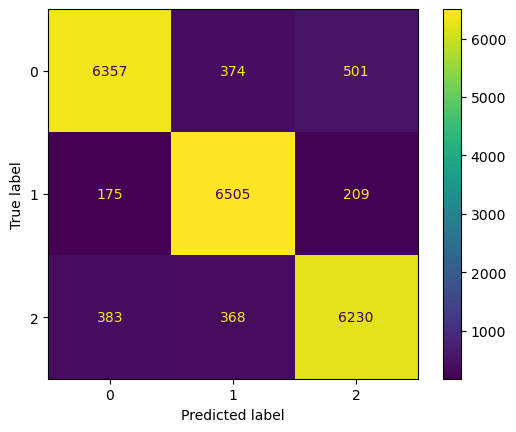

In [41]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred
)

plt.show()

In [84]:
def predict_sentiment(input_text):
    cleaned_text = text_cleaning_pipeline[:-1].transform(
        pd.Series([input_text])
    ).iloc[0]

    sequence = tokenizer.texts_to_sequences([cleaned_text])

    padded_sequence = pad_sequences(
        sequence,
        maxlen=max_length,
        padding='post'
    )

    prediction = model.predict(padded_sequence, verbose=0)

    sentiment_labels = ['Negative', 'Neutral', 'Positive']

    return sentiment_labels[np.argmax(prediction)]

In [86]:
input_text = "good"

predicted_sentiment = predict_sentiment(input_text)

print("Predicted Sentiment:", predicted_sentiment)

Predicted Sentiment: Positive


In [88]:
test_comments = [
    "This is absolutely wonderful and amazing",
    "Worst experience ever, completely disappointed",
    "The video was uploaded yesterday"
]

for comment in test_comments:
    print(comment, "->", predict_sentiment(comment))

This is absolutely wonderful and amazing -> Positive
Worst experience ever, completely disappointed -> Negative
The video was uploaded yesterday -> Neutral


In [90]:
import os

os.makedirs("artifacts", exist_ok=True)

In [92]:
model.save("artifacts/sentiment_model.keras")

In [94]:
with open("artifacts/tokenizer.json", "w") as f:
    f.write(tokenizer.to_json())

In [96]:
import json

config = {
    "vocab_size": vocab_size,
    "max_features": max_features,
    "max_length": max_length,
    "embedding_dim": embedding_dim,
    "classes": ["Negative", "Neutral", "Positive"]
}

with open("artifacts/config.json", "w") as f:
    json.dump(config, f, indent=4)

In [98]:
print(os.listdir("artifacts"))

['config.json', 'sentiment_model.keras', 'tokenizer.json']
